In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression

# **`1. Exploratory Data Analysis (EDA):`**



**Perform exploratory data analysis to understand the structure of the dataset.**

In [29]:
file = 'glass.xlsx'
xls = pd.ExcelFile(file)
print(xls.sheet_names)

['Description', 'glass']


In [30]:
df = pd.read_excel(file, sheet_name=1)

In [31]:
df.shape

(214, 10)

In [32]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


**Check for missing values, outliers, inconsistencies in the data.**

In [34]:
#missing values
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [35]:
#duplicates
df.duplicated().sum()

np.int64(1)

In [36]:
df.drop_duplicates(inplace=True)

In [37]:
df.duplicated().sum()

np.int64(0)

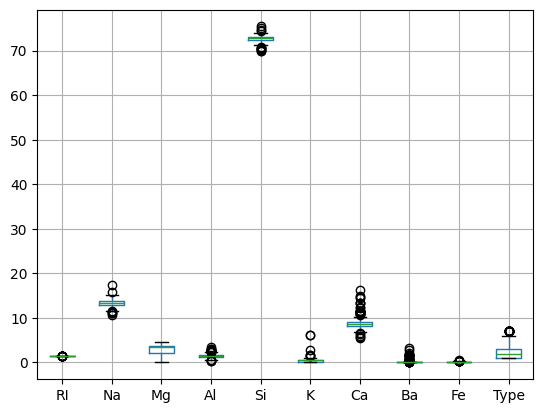

In [38]:
#outliers
df.boxplot()
plt.show()

In [39]:
#outlier capping
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int', 'float']).columns:
  outlier_capping(df, col)

Explanation:
---

In this step, i performmed EDA and also checked for missing values and duplicates. Then i dropped duplicated row and then checked outliers using boxplot, treated them by outlier capping.

# **`2. Data Visualization:`**



**Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.**

HISTOGRAM:
---

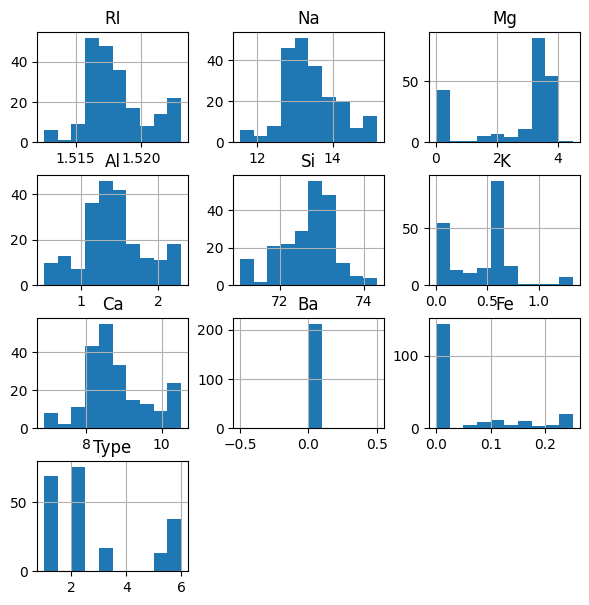

In [40]:
df.hist(figsize=(7,7))
plt.show()

BOX PLOTS:
---

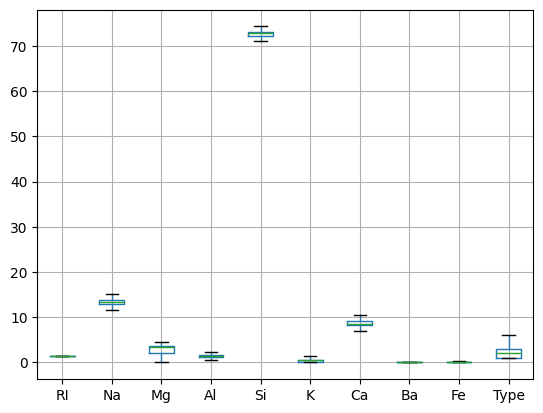

In [41]:
df.boxplot()
plt.show()

PAIR PLOT:
---

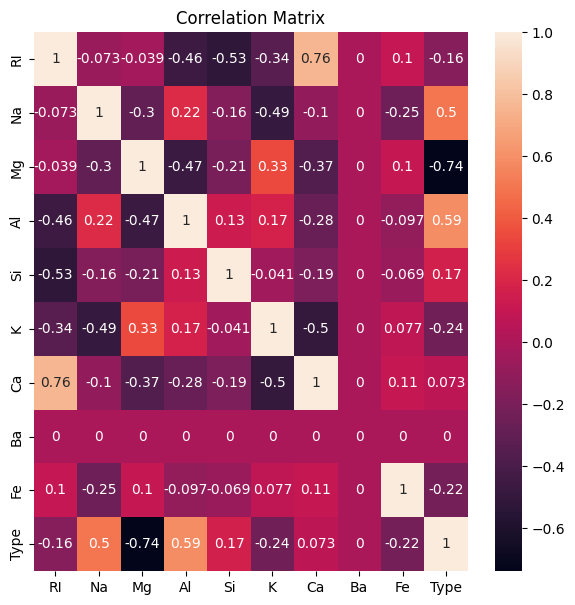

In [42]:
plt.figure(figsize=(7, 7))
corr = df.select_dtypes(include = ['int64', 'float64']).corr()

sns.heatmap(corr.fillna(0), annot = True)
plt.title('Correlation Matrix')
plt.show()

**Analyze any patterns or correlations observed in the data.**

From the correlation matrix, we can observe that most feature have low to moderate correlation with each other,(they are not dtrongly dependent). Some pairs shows positive correlation(values near +1), which means both features increase together, and some show negative correlation(values near -1), which means one feature increases while the other decreases.
overall, the dataset does not have many highly correlated features, which is good because it reduces redundancy and helps the model learn better.

Explanation:
---

In this step, we visualized the dataset using histogram, box plot and a correlation heatmap to understand feature relationships and patterns. We used fillna(0) because sometimes correlation values become NaN, which creates white blank spaces in the heatmap, so replacing them with 0 helps display the matrix properly. From the heatmap, we observed that most features have low/moderate correlation, while a few features show positive or negative relationships.

# **`3. Data Preprocessing:`**

**1. Check for missing values in the dataset and decide on a strategy for handling them. Implement the chosen strategy (e.g., imputation or removal) and explain your reasoning.**



In [43]:
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [44]:
#duplicates
df.duplicated().sum()

np.int64(0)

In this preprocessing step, I checked for missing values using df.isnull().sum(). The result showed 0 missing values in all columns, so no imputation was needed.

Next, I checked for duplicates using df.duplicated().sum() and found 1 duplicate row. Duplicate records can affect model learning by repeating the same data, so we dropped that duplicate row to keep the dataset clean and accurate.


**2. If there are categorical variables, apply encoding techniques like one-hot encoding to convert them into numerical format.**


In [45]:
cat_cols = df.select_dtypes(include='object').columns
cat_cols

Index([], dtype='object')

**3. Apply feature scaling techniques such as standardization or normalization to ensure that all features are on a similar scale. Handling the imbalance data.**

In [46]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
num_cols

Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='object')

In [49]:
scale_cols = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe' ]

In [50]:
std_scaler = StandardScaler()
df[scale_cols] = std_scaler.fit_transform(df[scale_cols])

Explanation:
---

Since all feature columns are numerical and the target is Type, there were no categorical columns, so no encoding was required. Finally, we applied StandardScaler only on the feature columns (RI, Na, Mg, Al, Si, K, Ca, Ba, Fe) to bring them to the same scale, while keeping the target column (Type) separate because it is the class label to predict.

# **`4. Random Forest Model Implementation:`**



**1. Divide the data into train and test split.**

In [53]:
target = df[['Type']]
features = df.drop(columns = ['Type'])

In [68]:
x_train, x_test, y_train, y_test = train_test_split(features, target, train_size=0.8, random_state=50, stratify=target)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(170, 9)
(43, 9)
(170, 1)
(43, 1)


**2. Implement a Random Forest classifier using Python and a machine learning library like scikit-learn.**


In [69]:
ran_for = RandomForestClassifier()
ran_for.fit(x_train, y_train)

RandomForestClassifier()

**3. Train the model on the train dataset. Evaluate the performance on test data using metrics like accuracy, precision, recall, and F1-score.**

In [70]:
y_pred = ran_for.predict(x_test)

In [71]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted')
rec = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

In [72]:
print(f'Accuracy: {acc}')
print(f'Precision: {prec}')
print(f'Recall: {rec}')
print(f'F1-score: {f1}')

Accuracy: 0.813953488372093
Precision: 0.8295485636114911
Recall: 0.813953488372093
F1-score: 0.8063652766639935


Explanation:
---

First, separated the dataset into features and target (Type), then split the data into training and testing sets (80–20 split). After that, we created and trained a RandomForestClassifier, predicted the test results using predict, and evaluated the model using accuracy, precision, recall, and F1-score. We used average="weighted" for precision/recall/F1 because the problem is multi-class, and weighted average gives a balanced overall score by considering the size of each class.

# **`5. Bagging and Boosting Methods:`**



**Apply the Bagging and Boosting methods and compare the results.**

Bagging
---

In [77]:
bag_class = BaggingClassifier(estimator=LogisticRegression(), n_estimators=100, max_samples=1.0, max_features=1.0, bootstrap=True, bootstrap_features=True)
bag_class.fit(x_train, y_train)

BaggingClassifier(bootstrap_features=True, estimator=LogisticRegression(),
                  n_estimators=100)

In [79]:
y_pred = bag_class.predict(x_test)
acc = accuracy_score(y_test, y_pred)
acc

0.6976744186046512

Boosting
---

In [81]:
ada_boost = AdaBoostClassifier(estimator=LogisticRegression(), n_estimators=100)
ada_boost.fit(x_train, y_train)

AdaBoostClassifier(estimator=LogisticRegression(), n_estimators=100)

In [82]:
y_pred = ada_boost.predict(x_test)
acc = accuracy_score(y_test, y_pred)
acc

0.6046511627906976

Explanation
---

I used BaggingClassifier with LogisticRegression as the estimator and trained multiple models (n_estimators=100) on different random samples, then predicted on test data and calculated accuracy, which came around 0.69. Next, for boosting I choose AdaBoostClassifier, where models are trained one after another and each new model focuses more on the previous model’s mistakes, and after evaluation the accuracy came around 0.60. So overall, in my results Bagging performed better than Boosting for this dataset.